# Background Model Example

This example shows how to load the data, create the `SNSensitivityEstimate.DataProcess` objects and obtain the expected background counts for each process.

In [1]:
import Pkg;
Pkg.activate("..")
using SNSensitivityEstimate, UnROOT, FHist, CairoMakie, CSV, DataFramesMeta

  Activating project at `/sps/nemo/scratch/mpetro/Sensitivity_training`
Precompiling CairoMakie
  ? Makie
        Info Given CairoMakie was explicitly requested, output will be shown live 
ERROR: Method overwriting is not permitted during Module precompilation. Use `__precompile__(false)` to opt-out of precompilation.
  ? CairoMakie
[ Info: Precompiling CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0]
ERROR: Method overwriting is not permitted during Module precompilation. Use `__precompile__(false)` to opt-out of precompilation.
[ Info: Skipping precompilation since __precompile__(false). Importing CairoMakie [13f3f980-e62b-5c42-98c6-ff1f3baf88f0].
Precompiling Makie
        Info Given Makie was explicitly requested, output will be shown live 
ERROR: Method overwriting is not permitted during Module precompilation. Use `__precompile__(false)` to opt-out of precompilation.
  ? Makie
[ Info: Precompiling Makie [ee78f7c6-11fb-53f2-987a-cfe4a2b5a57a]
ERROR: Method overwriting is not perm

## Step 1: Load the data

### Step 1.1: Load the file index

We start by loading the `data/data_info.csv` file which holds the information about the data files we want to analyze. This file contains the paths to the ROOT files and the corresponding necessary information to process them.

In [3]:
data_info = CSV.read("../data/data_info.csv", DataFrame)

Row,file_name,process,is_signal,activity,amount,time_s,n_sim
,String31,String31,Bool,Float64,Float64,Float64,Float64
1,Bi214_foil_bulk.root,Bi214_foil_bulk,false,1.0e-5,6.25,9.0193e7,1.0e8
2,Bi214_wire_surface.root,Bi214_wire_surface,false,0.00015,15.0,9.0193e7,1.0e8
3,Tl208_foil_bulk.root,Tl208_foil_bulk,false,2.0e-6,6.25,9.0193e7,1.0e8
4,bb0nu_foil_bulk.root,bb0nu_foil_bulk,true,1.61577e-9,6.25,9.0193e7,1.0e7
5,bb_foil_bulk.root,bb_foil_bulk,false,0.00185935,6.25,9.0193e7,1.0e8


### Step 1.2: Load the ROOT files

We then load the data files specified in the `data_info` DataFrame.

In [5]:
# the . in julia is used to broadcast operations over arrays.
file_paths = joinpath.("/sps/nemo/scratch/mpetro/Sensitivity_training/data", data_info.file_name)

# The [x for x in y] in julia is a list comprehension that creates a new array by applying the expression x to each element in the array y.
data_files = [UnROOT.ROOTFile(file_path) for file_path in file_paths]

5-element Vector{ROOTFile}:
 ROOTFile with 1 entry and 19 streamers.
/sps/nemo/scratch/mpetro/Sensitivity_training/data/Bi214_foil_bulk.root
└─ tree (TTree)
   ├─ "phi"
   ├─ "sameSide"
   ├─ "dz"
   ├─ "⋮"
   ├─ "z2Reconstructed"
   ├─ "caloTime1"
   └─ "caloTime2"

 ROOTFile with 1 entry and 19 streamers.
/sps/nemo/scratch/mpetro/Sensitivity_training/data/Bi214_wire_surface.root
└─ tree (TTree)
   ├─ "phi"
   ├─ "sameSide"
   ├─ "dz"
   ├─ "⋮"
   ├─ "z2Reconstructed"
   ├─ "caloTime1"
   └─ "caloTime2"

 ROOTFile with 1 entry and 19 streamers.
/sps/nemo/scratch/mpetro/Sensitivity_training/data/Tl208_foil_bulk.root
└─ tree (TTree)
   ├─ "phi"
   ├─ "sameSide"
   ├─ "dz"
   ├─ "⋮"
   ├─ "z2Reconstructed"
   ├─ "caloTime1"
   └─ "caloTime2"

 ROOTFile with 1 entry and 19 streamers.
/sps/nemo/scratch/mpetro/Sensitivity_training/data/bb0nu_foil_bulk.root
└─ tree (TTree)
   ├─ "phi"
   ├─ "sameSide"
   ├─ "dz"
   ├─ "⋮"
   ├─ "z2Reconstructed"
   ├─ "caloTime1"
   └─ "caloTime2"

 ROOTFile

### Step 1.3: Turn `UnROOT.ROOTFile` objects into `LazyTree` tabular objects

In [6]:
tree_name = "tree" # name of the root tree
variables = keys(data_files[1][tree_name]) # get the variable names from the first file

data_tables = [UnROOT.LazyTree(data_file, tree_name, variables) for data_file in data_files]

5-element Vector{LazyTree with 26 branches:
sameSide, reconstructedEnergy2, Pext, avgE, z2Reconstructed...
}:
 ┌─────┬──────────┬─────────────────┬────────────┬───────────┬───────────────────
│ Row │ sameSide │ reconstructedEn │ Pext       │ avgE      │ z2Reconstructed  ⋯
│     │ Float32  │ Float32         │ Float32    │ Float32   │ Float32          ⋯
├─────┼──────────┼─────────────────┼────────────┼───────────┼───────────────────
│ 1   │ 0.0      │ 417.84256       │ 2.062762e- │ 539.3591  │ 36.14118         ⋯
│ 2   │ 1.0      │ 66.81933        │ 0.4553107  │ 872.25037 │ -62.85587        ⋯
│ 3   │ 1.0      │ 286.42862       │ 7.6636536e │ 1108.881  │ 796.15796        ⋯
│ 4   │ 0.0      │ 163.08542       │ 0.00024017 │ 701.16925 │ -1109.882        ⋯
│ 5   │ 0.0      │ 420.899         │ 5.03516e-1 │ 474.4948  │ -773.49896       ⋯
│ 6   │ 0.0      │ 771.45776       │ 3.876098e- │ 1004.4069 │ 591.2683         ⋯
│ 7   │ 0.0      │ 1874.1747       │ 1.8641002e │ 1229.9344 │ 57.884754        

### (Optional) Step 1.4: Inspect the loaded data

We can inspect the loaded data by printing the first few rows of the first data table.

In [6]:
println(first(data_tables[1], 5)) # print the first 5 rows of the first data table

┌─────┬──────────┬─────────────────┬────────────┬───────────┬───────────────────
│ Row │ sameSide │ reconstructedEn │ Pext       │ avgE      │ z2Reconstructed  ⋯
│     │ Float32  │ Float32         │ Float32    │ Float32   │ Float32          ⋯
├─────┼──────────┼─────────────────┼────────────┼───────────┼───────────────────
│ 1   │ 0.0      │ 417.84256       │ 2.062762e- │ 539.3591  │ 36.14118         ⋯
│ 2   │ 1.0      │ 66.81933        │ 0.4553107  │ 872.25037 │ -62.85587        ⋯
│ 3   │ 1.0      │ 286.42862       │ 7.6636536e │ 1108.881  │ 796.15796        ⋯
│ 4   │ 0.0      │ 163.08542       │ 0.00024017 │ 701.16925 │ -1109.882        ⋯
│ 5   │ 0.0      │ 420.899         │ 5.03516e-1 │ 474.4948  │ -773.49896       ⋯
└─────┴──────────┴─────────────────┴────────────┴───────────┴───────────────────
                                                              21 columns omitted



### (Optional) Step 1.5: Visualize variable distributions

We can also visualize the distributions of selected variables and processes using the CairoMakie package. In this example, we will plot the distributions of the `sumE` variable for each process.

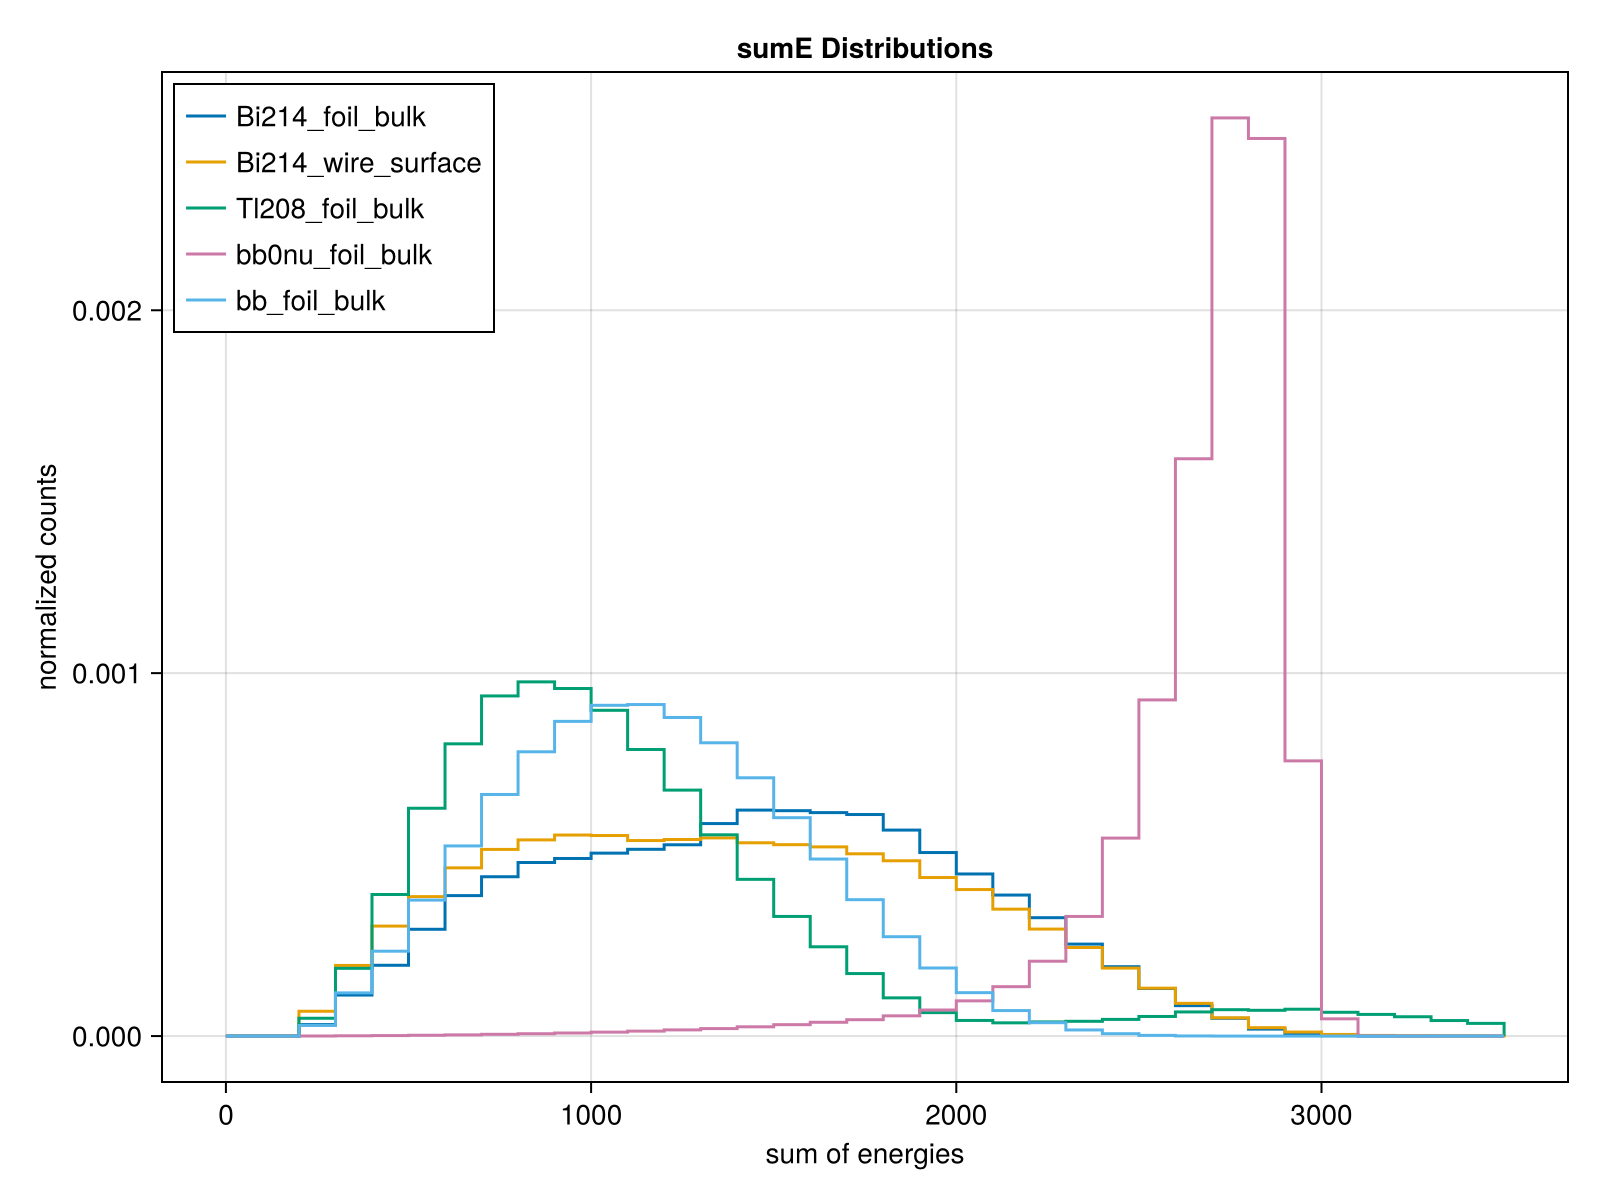

In [7]:
let
    binning = 0:100:3500 # define the binning for the histogram in format start:step:end

    f = CairoMakie.Figure(size = (800, 600))
    a = CairoMakie.Axis(f[1, 1], title = "sumE Distributions", xlabel = "sum of energies", ylabel = "normalized counts")

    for (i, data_table) in enumerate(data_tables)
        process_name = data_info.process[i]
        sumE_values = data_table.sumE # extract the sumE values from the data table
        hist = FHist.Hist1D(sumE_values; binedges = binning) # create a normalized histogram
        hist = FHist.normalize(hist) # normalize the histogram
        CairoMakie.stephist!(a, hist, label = process_name) # plot the histogram as a line plot
    end

    CairoMakie.axislegend(a, position = :lt) # add a legend to the plot
    f
end

## Step 2: Create `SNSensitivityEstimate.DataProcess` objects

This is the basic data structure of the `SNSensitivityEstimate` package. It holds the data and the necessary information to perform the sensitivity analysis.

The following fields are defined for the `SNSensitivityEstimate.DataProcess` structure:

- `dataVector::Vector{<:Real}` — vector of initial data points
- `isotopeName::String` — isotope name
- `signal::Bool` — signal or background
- `activity::Real` — activity of the given process in units [Bq/x]
- `timeMeas::Real` — time of measurement in units [s]
- `nTotalSim::Real` — total number of originally simulated events from Falaise
- `bins::AbstractRange` — binning to be used in format `(min:step:max)`
- `amount::Real` — mass [kg] or volume [l / m³] of the object where the isotope is present: i.e. source foil
- `efficiency::Hist2D` — the 2D histogram with efficiencies per bin

In [8]:
processes = [
    SNSensitivityEstimate.DataProcess(
        collect(data_tables[i].sumE), # Here we specify a single variable to be used. In later stages we will use N-dimensional data vectors.
        String(data_info.process[i]),
        data_info.is_signal[i],
        data_info.activity[i],
        data_info.time_s[i],
        data_info.n_sim[i],
        0:100:3500,
        data_info.amount[i],
    ) for i in 1:length(data_tables)
]

5-element Vector{DataProcess}:
 DataProcess(Float32[1078.7181, 1744.5007, 2217.762, 1402.3385, 948.9896, 2008.8138, 2459.869, 2113.3574, 785.62964, 378.77924  …  1739.851, 1828.6782, 759.1842, 2033.6421, 1678.8, 2434.046, 1584.2197, 687.5069, 1062.26, 1781.6593], "Bi214_foil_bulk", false, 1.0e-5, 9.019296e7, 1.0e8, 0:100:3500, 6.25, edges: ([0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0], [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0])
bin counts: [0.0 0.0 … 0.00275267 0.00275267; 0.0 0.0 … 0.00275267 0.00275267; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0]
total count: 0.7809413399999999)
 DataProcess(Float32[1264.1129, 1791.3977, 2280.1206, 616.6037, 1219.7316, 984.1487, 691.69116, 1638.87, 1393.0671, 1100.311  …  808.7495, 2122.5254, 2346.385, 2439.28, 1372.8129, 473.25546, 326.69

## Step 3: Get the background counts histogram for each process

This is done using the `SNSensitivityEstimate.get_bkg_counts_1D` function.

To calculate the expected background counts we use the following equation:

$$n_i = a_i \cdot m_i \cdot t \cdot e_i$$

where, for the $i$-th bin:

- $n_i$ is the expected number of background counts in units [counts]
- $a_i$ is activity in units [Bq/x]
- $m_i$ is the amount $x$ of the process in units [x]
- $t$ is the time of measurement in units [s]
- $e_i$ is the efficiency of the process in units [1/s]

$e_i$ is calculated as $e_i = n_{pass,i} / n_{sim}$, where $n_{pass,i}$ is the number of events that pass the cuts in the $i$-th bin and $n_{sim}$ is the total number of simulated events.

In [9]:
# we can define a simple function that calculates n_i by defining the edges of the i-th bin:
function get_n_i(process::SNSensitivityEstimate.DataProcess, bin_lower::Real, bin_high::Real)
    n_pass_i = 0
    for i in 1:length(process.dataVector)
        if process.dataVector[i] >= bin_lower && process.dataVector[i] < bin_high
            n_pass_i += 1
        end
    end
    e_i = n_pass_i / process.nTotalSim
    n_i = process.activity * process.amount * process.timeMeas * e_i
    return n_i
end

get_n_i (generic function with 1 method)

Let's test $n_i$ for `bb_foil_bulk` in the bin defined by 2000–2100 keV:

In [10]:
n_i_test = get_n_i(processes[5], 2000, 2100)
println("Expected background counts for bb_foil_bulk in bin 2000-2100 keV: ", round(n_i_test, digits=2), " counts")

Expected background counts for bb_foil_bulk in bin 2000-2100 keV: 1896.2 counts


Repeating this process we could build a full histogram by finding out how many events we expect in each bin for each process.

Luckily, the `SNSensitivityEstimate` package has a built-in function that does this for us. The function is called `get_bkg_counts_1D` and it takes a `SNSensitivityEstimate.DataProcess` object as input and returns a histogram of expected background counts for each bin.

In [11]:
bb_histogram = get_bkg_counts_1D(processes[5]) # get the background counts for the bb_foil_bulk process

edges: [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
bin counts: [0.0, 0.0, 464.35034729868994, 1886.8536717920856, 3706.5645242537553, 5937.622096578288, 8302.021996021387, 10548.43458400609, 12412.093273097864, 13740.590361785062  …  31.44371807543665, 6.728955668143443, 1.079567653923325, 0.10481239358478883, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
total count: 158443.79485199263

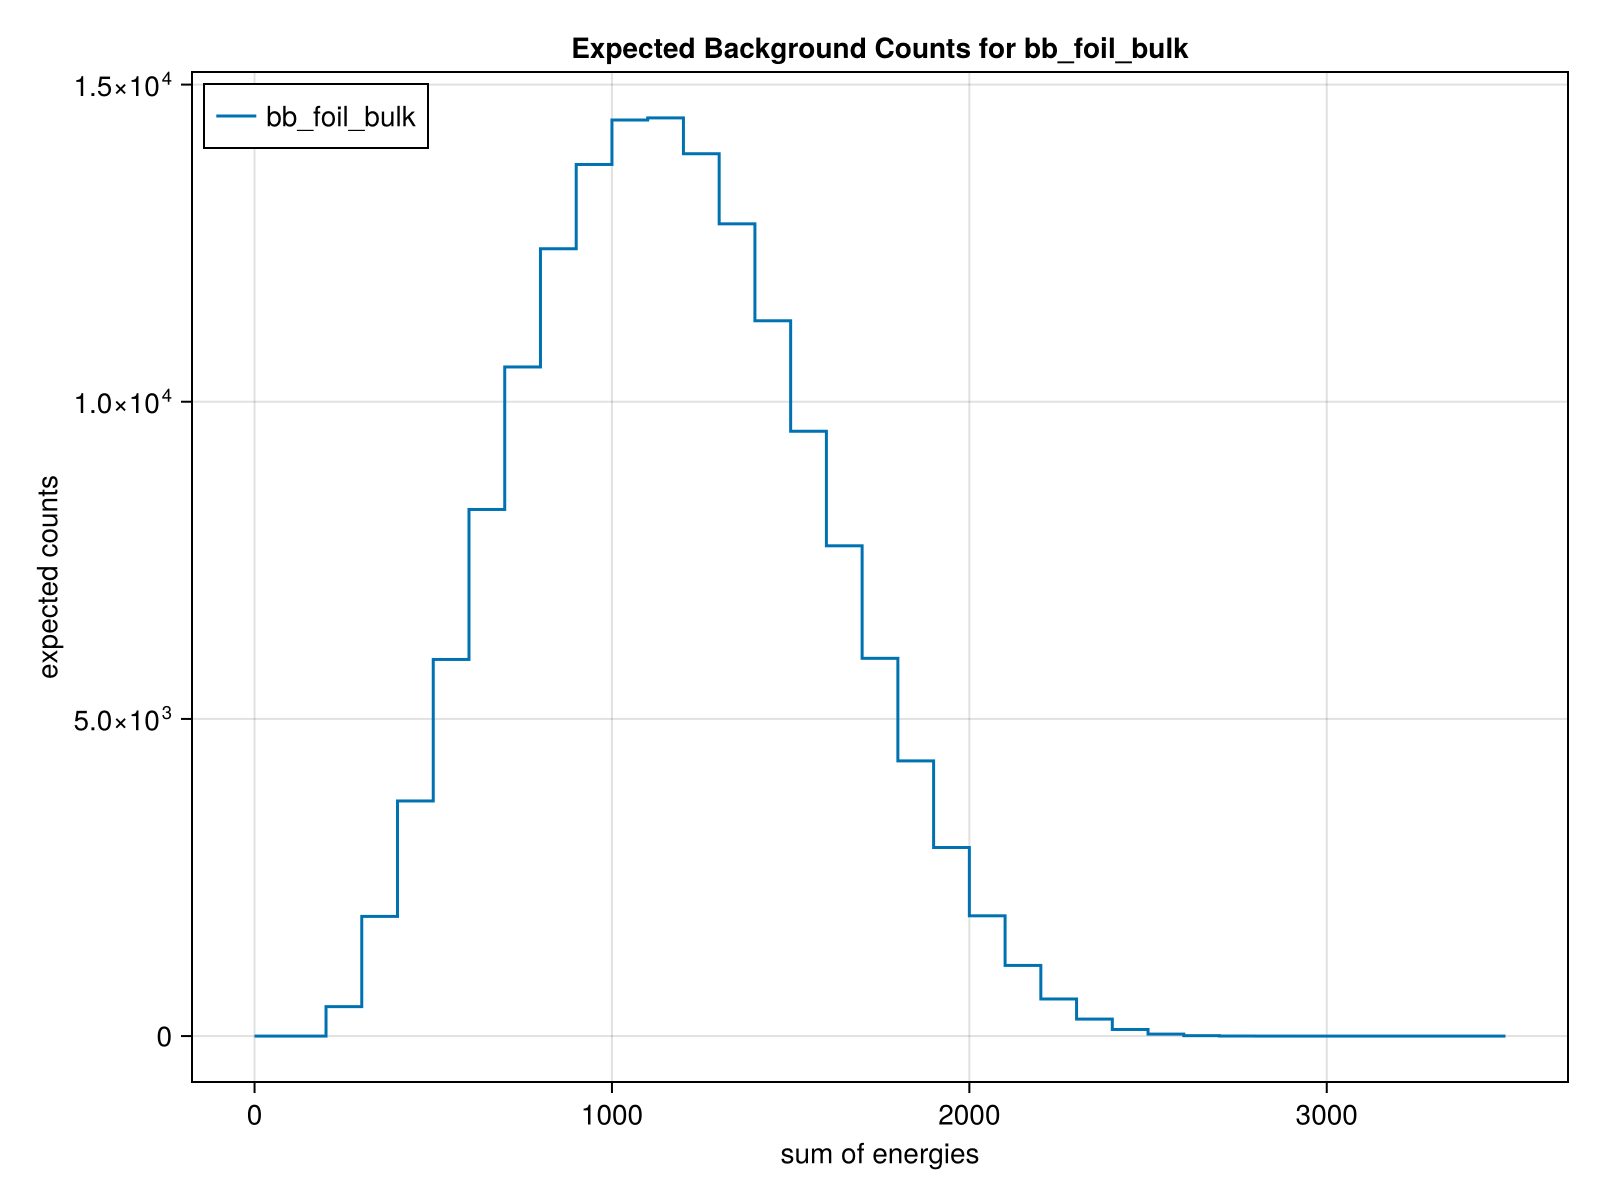

In [12]:
# plot the histogram
let
    f = CairoMakie.Figure(size = (800, 600))
    a = CairoMakie.Axis(f[1, 1], title = "Expected Background Counts for bb_foil_bulk", xlabel = "sum of energies", ylabel = "expected counts")
    CairoMakie.stephist!(a, bb_histogram, label = "bb_foil_bulk")
    CairoMakie.axislegend(a, position = :lt)
    f
end

Or even simpler, we can get all histograms at once by using the `get_bkg_counts_1D` function on the array of processes:

In [13]:
filter!(p -> !p.signal, processes) # filter out the signal processes
all_histograms = get_bkg_counts_1D.(processes)

4-element Vector{Hist1D{Float64}}:
 edges: [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
bin counts: [0.0, 0.0, 0.049155163200000004, 0.1754253072, 0.3027664926, 0.4566582306, 0.600628743, 0.6812950716, 0.7421753195999999, 0.7593683526  …  0.2033851248, 0.13015971540000001, 0.07610030999999999, 0.029876418000000002, 0.009583002, 0.0020857122, 0.0001691118, 5.63706e-5, 0.0, 0.0]
total count: 15.5169659502
 edges: [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
bin counts: [0.0, 0.0, 2.4555449819940303, 6.98917100660119, 10.879484833446277, 13.793668795548282, 16.638853973032276, 18.463263013373293, 19.404893485807367, 19.88585560211529  …  4.740622378461202, 3.238884125010308, 1.808174032195604, 0.8320441674525226, 0.4018164515990231, 0.16235008145415075, 0.06696940859983719, 0.02

## Step 4: Plot the stacked histogram and extract counts per process

### Step 4.1: Plot the stacked histogram

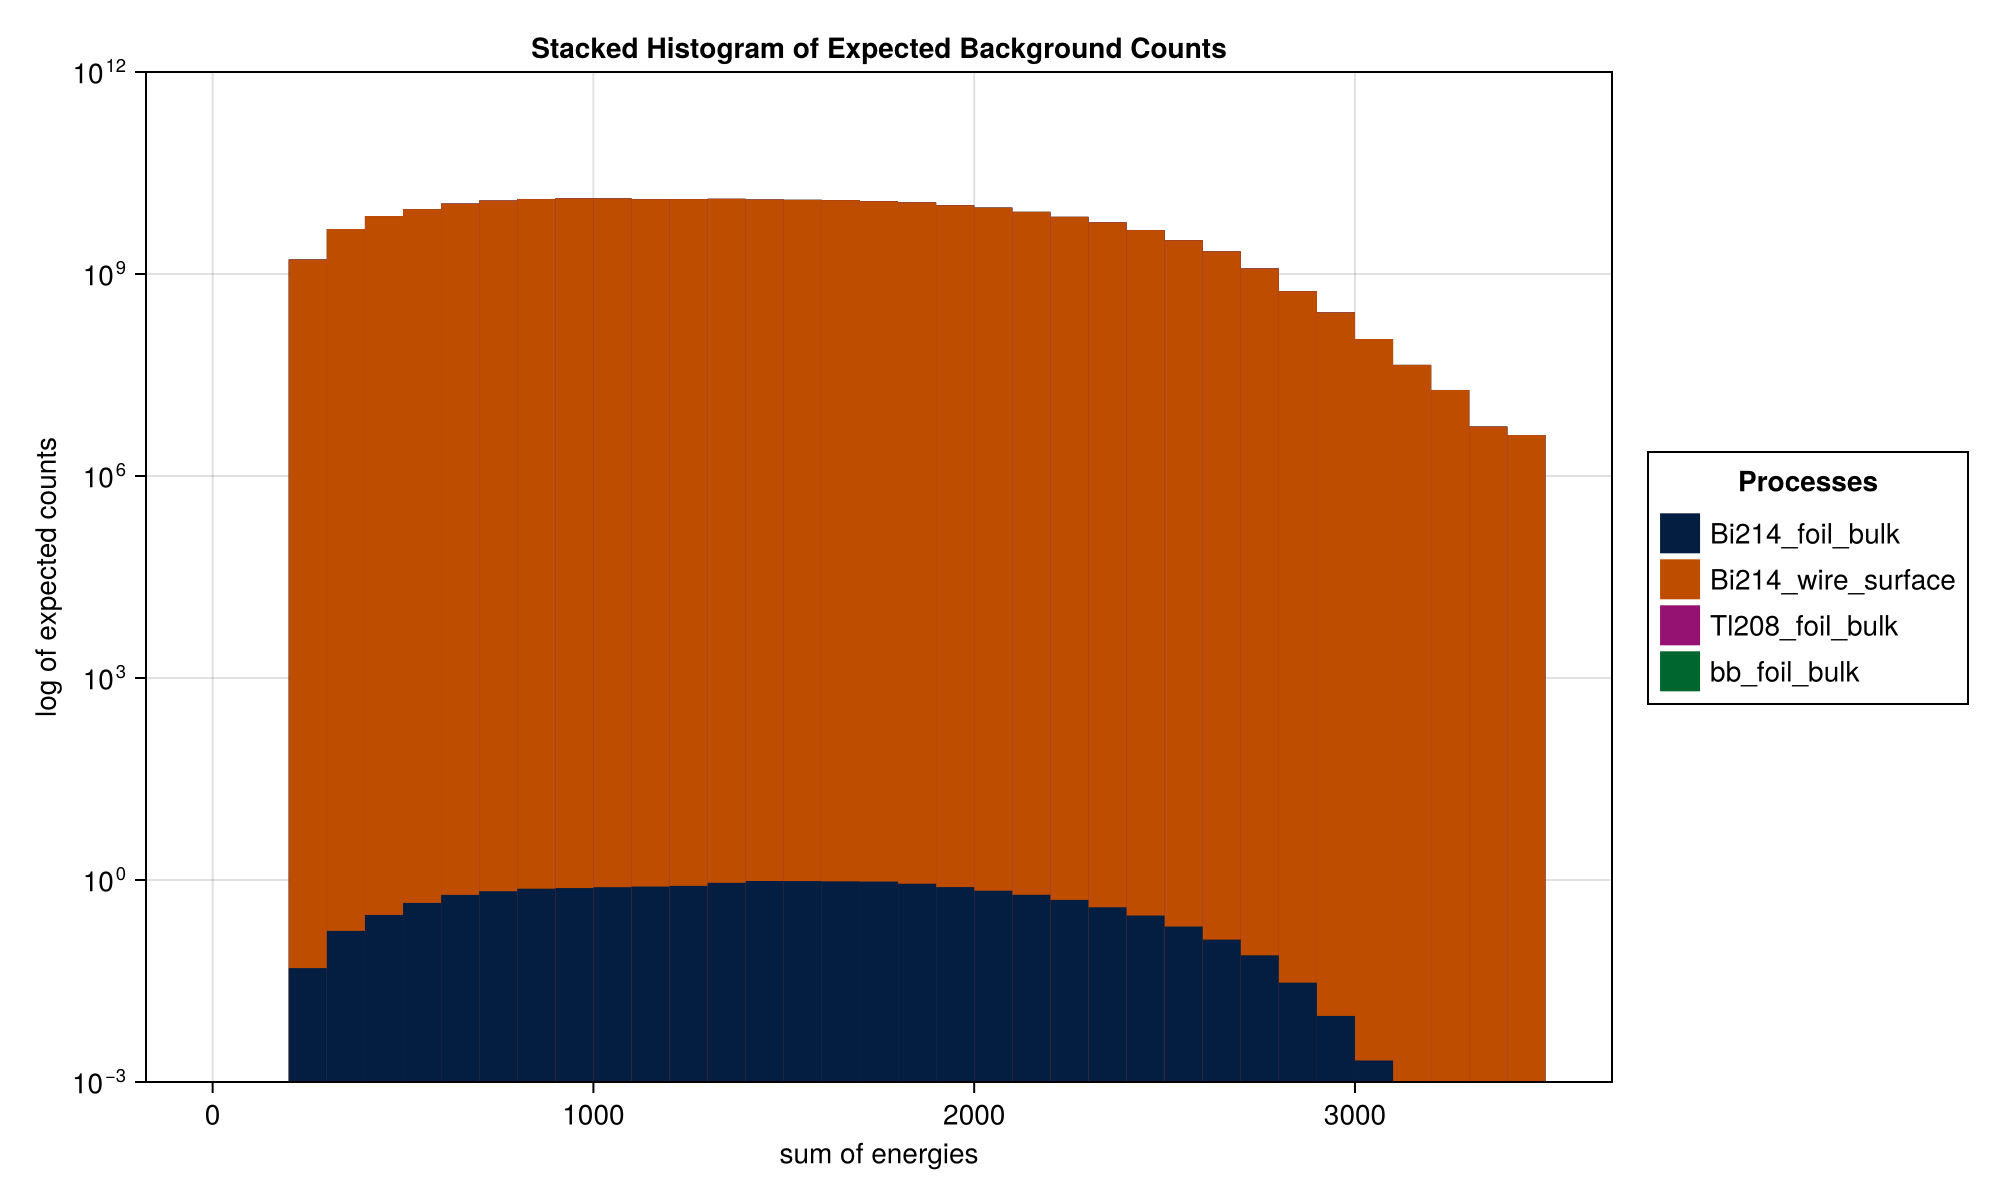

In [29]:
let
    colors = ["#041E42", "#BE4D00", "#951272", "#006630", "#005C8A", "#FFB948", "#605643", "#302D23"] # get our supernemo colors
    f = CairoMakie.Figure(size = (1000, 600))
    a = CairoMakie.Axis(f[1, 1], title = "Stacked Histogram of Expected Background Counts", xlabel = "sum of energies", ylabel = "log of expected counts", yscale = log10)
    p = CairoMakie.hist!(a, sum(all_histograms), color = colors[1])
    for i in length(all_histograms):-1:1
        CairoMakie.hist!(a, sum(all_histograms[1:i]), color = colors[i])
    end

    labels = [String(p.isotopeName) for p in processes]
    elements = [CairoMakie.PolyElement(polycolor = colors[i]) for i in 1:length(labels)]
    title = "Processes"
    
    ylims!(a, 1e-3, 1e12)
    CairoMakie.Legend(f[1,2], elements, labels, title)
    save("/sps/nemo/scratch/mpetro/Sensitivity_training/data/out/ex1/stacked_background_histogram.png", f)
    f
end

### Step 4.2: Get counts per process and save to a table

We integrate each histogram to get the total counts per process.

In [15]:
counts_per_process = [integral(hist) for hist in all_histograms] # we integrate each histogram to get the total counts per process
df_counts_per_process = DataFrame(isotopeName = [String(p.isotopeName) for p in processes], counts = counts_per_process)
CSV.write("/sps/nemo/scratch/mpetro/Sensitivity_training/data/out/ex1/counts_per_process.csv", df_counts_per_process)

"/sps/nemo/scratch/mpetro/Sensitivity_training/data/out/ex1/counts_per_process.csv"

### Step 4.3: Get counts in the region of interest (ROI)

We first restrict the histogram to the ROI and then integrate to get the total counts per process in the ROI.

In [16]:
a,b = 2700, 3000
counts_per_process_roi = [integral(restrict(hist, a, b)) for hist in all_histograms] # we first restrict the histogram to the ROI and then integrate to get the total counts per process in the ROI
df_counts_per_process_roi = DataFrame(isotopeName = [String(p.isotopeName) for p in processes], counts = counts_per_process_roi)
CSV.write("/sps/nemo/scratch/mpetro/Sensitivity_training/data/out/ex1/counts_per_process_roi.csv", df_counts_per_process_roi)

"/sps/nemo/scratch/mpetro/Sensitivity_training/data/out/ex1/counts_per_process_roi.csv"

In [18]:
for i in 1:length(processes)
    @show i, processes[i].isotopeName
end

(i, (processes[i]).isotopeName) = (1, "Bi214_foil_bulk")
(i, (processes[i]).isotopeName) = (2, "Bi214_wire_surface")
(i, (processes[i]).isotopeName) = (3, "Tl208_foil_bulk")
(i, (processes[i]).isotopeName) = (4, "bb_foil_bulk")


In [30]:
set_activity!(processes[2], 0.00010)

DataProcess(Float32[1264.1129, 1791.3977, 2280.1206, 616.6037, 1219.7316, 984.1487, 691.69116, 1638.87, 1393.0671, 1100.311  …  808.7495, 2122.5254, 2346.385, 2439.28, 1372.8129, 473.25546, 326.6947, 2135.1484, 1852.362, 1386.1583], "Bi214_wire_surface", false, 0.0001, 9.019296e7, 1.0e8, 0:100:3500, 15.0, edges: ([0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0], [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0])
bin counts: [0.0 0.0 … 0.00176881 0.00176884; 0.0 0.0 … 0.00176881 0.00176884; … ; 0.0 0.0 … 4.0e-8 7.0e-8; 0.0 0.0 … 0.0 3.0000000000000004e-8]
total count: 0.48705422)

In [31]:
processes[2].activity

0.0001

In [32]:
all_histograms = get_bkg_counts_1D.(processes)

4-element Vector{Hist1D{Float64}}:
 edges: [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
bin counts: [0.0, 0.0, 0.049155163200000004, 0.1754253072, 0.3027664926, 0.4566582306, 0.600628743, 0.6812950716, 0.7421753195999999, 0.7593683526  …  0.2033851248, 0.13015971540000001, 0.07610030999999999, 0.029876418000000002, 0.009583002, 0.0020857122, 0.0001691118, 5.63706e-5, 0.0, 0.0]
total count: 15.5169659502
 edges: [0.0, 100.0, 200.0, 300.0, 400.0, 500.0, 600.0, 700.0, 800.0, 900.0  …  2600.0, 2700.0, 2800.0, 2900.0, 3000.0, 3100.0, 3200.0, 3300.0, 3400.0, 3500.0]
bin counts: [0.0, 0.0, 1.6370299879960204, 4.659447337734127, 7.252989888964185, 9.19577919703219, 11.09256931535485, 12.308842008915532, 12.936595657204913, 13.257237068076861  …  3.1604149189741353, 2.1592560833402055, 1.2054493547970695, 0.5546961116350152, 0.26787763439934875, 0.1082333876361005, 0.04464627239989146, 0.0